In [1]:
import os
from pathlib import Path

# Walk up until we find the repo root (identified by CLAUDE.md)
_here = Path(os.getcwd())
while not (_here / "CLAUDE.md").exists() and _here != _here.parent:
    _here = _here.parent
os.chdir(_here)
del _here

import duckdb
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import statsmodels.formula.api as smf
from scipy.stats import sem

%matplotlib inline

Path("results").mkdir(exist_ok=True)
Path("results/plots").mkdir(exist_ok=True)

DARK  = "#2c3e50"; MID  = "#7f8c8d"; GOLD  = "#e8b84b"
RED   = "#e74c3c"; BLUE = "#3498db"; GREEN = "#27ae60"; BG = "#f8f8f8"

MIN_SWINGS = 200
COMMIT_MS  = 150

# Empirical baseline columns: expected plate location from KNN on commit-time state
EMP_DEV_X   = f"pc{COMMIT_MS}_emp_dev_x"    # actual - KNN-expected plate_x
EMP_DEV_Z   = f"pc{COMMIT_MS}_emp_dev_z"    # actual - KNN-expected plate_z
EMP_X_PROJ  = f"pc{COMMIT_MS}_emp_x_proj"   # KNN-expected plate_x
EMP_Z_PROJ  = f"pc{COMMIT_MS}_emp_z_proj"   # KNN-expected plate_z

# Gravity-corrected linear deviation (spin-induced only, gravity stripped out)
LIN_DEV_X   = f"pc{COMMIT_MS}_dev_x"
LIN_DEV_Z   = f"pc{COMMIT_MS}_dev_z"

# Primary treatment columns used throughout (empirical baseline)
DEV_X = EMP_DEV_X
DEV_Z = EMP_DEV_Z

AXIS_COLS  = ("vert_attack_angle_dev", "horz_attack_angle_dev", "swing_path_tilt_dev")
AXIS_LBL   = {"vert_attack_angle_dev": "VAA",
              "horz_attack_angle_dev": "HAA",
              "swing_path_tilt_dev":   "Tilt"}


def _spine_clean(ax):
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    ax.spines["left"].set_color(MID)
    ax.spines["bottom"].set_color(MID)


def _eb_shrink(means, ns, within_var, between_var, grand):
    w = ns / (ns + within_var / between_var)
    return w * means + (1 - w) * grand

Path("results/plots/leaderboards").mkdir(parents=True, exist_ok=True)
Path("results/plots/validation").mkdir(parents=True, exist_ok=True)
Path("results/plots/diagnostics").mkdir(parents=True, exist_ok=True)
Path("results/plots/case_studies").mkdir(parents=True, exist_ok=True)
Path("results/plots/applications").mkdir(parents=True, exist_ok=True)


In [2]:
_cache = {}


def _load(key, fn):
    if key not in _cache:
        _cache[key] = fn()
    return _cache[key]


_PC_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "game_year",
    # Empirical baseline (KNN commit-time expected plate location)
    EMP_DEV_X, EMP_DEV_Z, EMP_X_PROJ, EMP_Z_PROJ,
    # Gravity-corrected linear deviation (spin-induced only)
    LIN_DEV_X, LIN_DEV_Z,
    "ball_bat_miss", "is_whiff",
    "is_contact", "is_bip", "is_single", "is_double", "is_triple", "is_home_run",
    "is_swing", "bat_speed", "count_group", "balls", "strikes", "vert_attack_angle",
    "pitcher_full_name", "pitch_type", "pfx_x", "pfx_z",
    f"pc{COMMIT_MS}_R_x", f"pc{COMMIT_MS}_R_y", f"pc{COMMIT_MS}_R_z",
    f"pc{COMMIT_MS}_V_x", f"pc{COMMIT_MS}_V_y", f"pc{COMMIT_MS}_V_z",
    f"pc{COMMIT_MS}_A_x", f"pc{COMMIT_MS}_A_y", f"pc{COMMIT_MS}_A_z",
    f"pc{COMMIT_MS}_t_plate",
])

_SXRV_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "pitcher_id", "pitcher_full_name",
    "pfx_x", "pfx_z", "release_speed", "release_extension", "arm_angle",
    "ivb_transverse", "hb_transverse", "pitcher_throws", "stuff_grade", "xrv_vs_count", "xrv",
])


def xrv():  return _load("xrv",  lambda: duckdb.sql("SELECT * FROM read_parquet('results/xrv_causal.parquet')").df())
def pc():   return _load("pc",   lambda: duckdb.sql(f"SELECT {_PC_COLS} FROM read_parquet('data/swings_precommit.parquet')").df())
def sxrv(): return _load("sxrv", lambda: duckdb.sql(f"SELECT {_SXRV_COLS} FROM read_parquet('results/swing_xrv.parquet')").df())


def merged():
    if "merged" in _cache:
        return _cache["merged"]
    pc_cols = ["game_pk", "at_bat_number", "pitch_number", "game_year",
               EMP_DEV_X, EMP_DEV_Z, LIN_DEV_X, LIN_DEV_Z, "ball_bat_miss", "is_whiff"]
    sx_cols = ["game_pk", "at_bat_number", "pitch_number", "pitcher_full_name",
               "pfx_x", "pfx_z", "release_speed", "release_extension", "arm_angle",
               "ivb_transverse", "hb_transverse", "pitcher_throws",
               "stuff_grade", "xrv_vs_count", "xrv"]
    K = ["game_pk", "at_bat_number", "pitch_number"]
    df = (xrv()
          .merge(pc()[pc_cols], on=K, how="left")
          .merge(sxrv()[sx_cols], on=K, how="left"))
    _cache["merged"] = df
    return df



_SXRV_EXT_COLS = ", ".join([
    "game_pk", "at_bat_number", "pitch_number", "pitcher_id",
    "batter_id", "batter_full_name", "game_year",
    "pitch_type", "pitch_group", "plate_x", "plate_z",
    "xwoba", "is_whiff", "is_bip", "stuff_grade", "xrv",
])

def sxrv_extended():
    return _load("sxrv_ext", lambda: duckdb.sql(
        f"SELECT {_SXRV_EXT_COLS} FROM read_parquet('results/swing_xrv.parquet')"
    ).df())

In [ ]:
# --- Level 1 controls ---
dev_col = duckdb.sql("""
    SELECT game_pk, at_bat_number, pitch_number, pc150_dev_total
    FROM read_parquet('data/swings_precommit.parquet')
""").df()

xrv_pc = (xrv()
          .merge(dev_col, on=["game_pk", "at_bat_number", "pitch_number"], how="left")
          .dropna(subset=["disruption_tax", "pc150_dev_total"]))

# --- Negative control: near-straight FF (post-commit deviation < 1 inch = 1/12 ft) ---
near_straight = xrv_pc.query("pitch_type == 'FF' and pc150_dev_total < (1/12)")
all_ff        = xrv_pc.query("pitch_type == 'FF'")
high_break    = xrv_pc.query("pitch_type in ['ST','SL','CU']")

neg_mean  = near_straight["disruption_tax"].mean()
neg_sem   = near_straight["disruption_tax"].sem()
ff_mean   = all_ff["disruption_tax"].mean()
break_mean = high_break["disruption_tax"].mean()

# --- Positive control: distortion_tax by pitch type ---
KEEP_TYPES = ["FF", "SI", "FC", "CH", "FS", "SL", "CU", "ST", "KC"]
pt_ctrl = (xrv_pc[xrv_pc["pitch_type"].isin(KEEP_TYPES)]
           .groupby("pitch_type")["distortion_tax"]
           .agg(n="size", mean="mean", sem=sem)
           .reset_index()
           .query("n >= 5000")
           .sort_values("mean"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), facecolor=BG)
for ax in (ax1, ax2):
    ax.set_facecolor(BG)

# --- Left panel: negative control distribution ---
_neg_lbl = f"Near-straight FF\n(n={len(near_straight)})"
ax1.hist(near_straight["disruption_tax"].clip(-0.15, 0.05), bins=40,
         color=BLUE, alpha=0.7, density=True, label=_neg_lbl)
ax1.axvline(neg_mean, color=RED, lw=1.5, linestyle="--",
            label=f"Mean = {neg_mean:.4f}")
ax1.axvline(0, color=DARK, lw=0.8)
ax1.set_xlabel("Disruption tax (xRV/swing)", color=DARK)
ax1.set_ylabel("Density", color=DARK)
ax1.set_title('Negative control\nNear-straight FF (post-commit dev < 1")',
              color=DARK, fontweight="bold")
ax1.legend(frameon=False, fontsize=8)
_spine_clean(ax1); ax1.tick_params(colors=DARK)

# --- Right panel: positive control bar chart ---
colors_bar = [RED if t in ["ST", "SL", "CU", "KC", "FS"] else BLUE for t in pt_ctrl["pitch_type"]]
ax2.barh(pt_ctrl["pitch_type"], pt_ctrl["mean"], xerr=pt_ctrl["sem"],
         color=colors_bar, height=0.6, capsize=3)
ax2.axvline(0, color=DARK, lw=0.8)
ax2.set_xlabel("Mean distortion tax (xRV/swing)  |  Negative = pitcher advantage", color=DARK)
ax2.set_title("Positive control\nDistortion tax by pitch type (red = breaking/offspeed)",
              color=DARK, fontweight="bold")
_spine_clean(ax2); ax2.tick_params(colors=DARK)

fig.tight_layout()
out = "results/plots/validation/level1_controls.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Near-straight FF mean disruption_tax: {neg_mean:.4f} \u00b1 {neg_sem:.4f}")
print(f"All FF mean: {ff_mean:.4f}  |  Breaking (ST/SL/CU) mean: {break_mean:.4f}")

assert Path(out).exists()
assert break_mean < ff_mean, f"Breaking balls should be more disruptive than FF: {break_mean:.4f} vs {ff_mean:.4f}"
assert pt_ctrl["pitch_type"].tolist()[0] in ["ST", "CU", "SL", "KC"], "Most disruptive pitch type should be a breaker"


# Axis Fingerprint

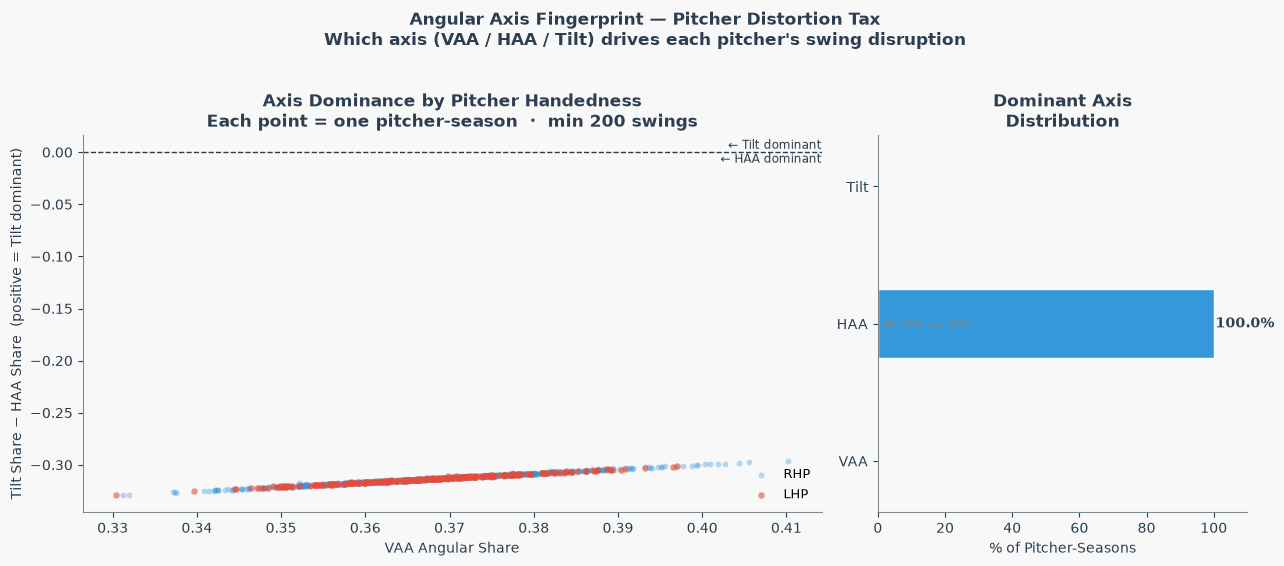

Saved results/plots/diagnostics/axis_fingerprint.png


In [4]:
csv = Path("results/axis_fingerprint.csv")
if not csv.exists():
    df = merged()
    models = joblib.load("models/causal_models.joblib")["mediator_models"]
    fp_cols = []
    for axis, m in models.items():
        col = f"_dd_{axis}"
        a_x = m.params.get(DEV_X, 0.0); a_z = m.params.get(DEV_Z, 0.0)
        df[col] = (a_x * df[DEV_X] + a_z * df[DEV_Z]).abs()
        fp_cols.append(col)
    fp = (df[df[DEV_X].notna()]
          .groupby(["pitcher_id", "pitcher_full_name", "game_year"])
          [fp_cols + ["distortion_tax"]]
          .agg(n=("distortion_tax", "size"), **{c: (c, "mean") for c in fp_cols})
          .reset_index()
          .query(f"n >= {MIN_SWINGS}"))
    total = fp[fp_cols].sum(axis=1).replace(0, np.nan)
    for col, axis in zip(fp_cols, AXIS_COLS):
        fp[f"{AXIS_LBL[axis]}_share"] = fp[col] / total
    fp["dominant_axis"] = fp[["VAA_share", "HAA_share", "Tilt_share"]].idxmax(axis=1)
    fp[["pitcher_id", "pitcher_full_name", "game_year", "n",
        "VAA_share", "HAA_share", "Tilt_share", "dominant_axis"]].to_csv(csv, index=False)
    df.drop(columns=fp_cols, inplace=True)

af = pd.read_csv(csv)
throws = sxrv()[["pitcher_id", "pitcher_throws"]].drop_duplicates("pitcher_id")
af = af.merge(throws, on="pitcher_id", how="left")
af["tilt_margin"] = af["Tilt_share"] - af["HAA_share"]

rhp = af[af["pitcher_throws"] == "R"]
lhp = af[af["pitcher_throws"] == "L"]
dom = af["dominant_axis"].value_counts()
n_tot = len(af)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), facecolor=BG,
                         gridspec_kw={"width_ratios": [2, 1]})
fig.patch.set_facecolor(BG)

ax = axes[0]; ax.set_facecolor(BG)
ax.scatter(rhp["VAA_share"], rhp["tilt_margin"],
           color=BLUE, alpha=0.35, s=18, linewidths=0, label="RHP")
ax.scatter(lhp["VAA_share"], lhp["tilt_margin"],
           color=RED,  alpha=0.60, s=22, linewidths=0, label="LHP")
ax.axhline(0, color=DARK, lw=1.0, ls="--")
xlim = ax.get_xlim()
ax.text(xlim[1], 0.0005, "← Tilt dominant", color=DARK, fontsize=8.5, ha="right", va="bottom")
ax.text(xlim[1], -0.0005, "← HAA dominant", color=DARK, fontsize=8.5, ha="right", va="top")
ax.set_xlabel("VAA Angular Share", color=DARK)
ax.set_ylabel("Tilt Share − HAA Share  (positive = Tilt dominant)", color=DARK)
ax.set_title("Axis Dominance by Pitcher Handedness\n"
             "Each point = one pitcher-season  ·  min 200 swings",
             color=DARK, fontweight="bold")
ax.legend(frameon=False, fontsize=9)
_spine_clean(ax); ax.tick_params(colors=DARK)

ax2 = axes[1]; ax2.set_facecolor(BG)
axis_names  = ["VAA", "HAA", "Tilt"]
axis_pcts   = [dom.get("VAA_share", 0) / n_tot * 100,
               dom.get("HAA_share",  0) / n_tot * 100,
               dom.get("Tilt_share", 0) / n_tot * 100]
axis_colors = [RED, BLUE, GREEN]
bars = ax2.barh(axis_names, axis_pcts, color=axis_colors, height=0.5, edgecolor="white")
for bar, pct in zip(bars, axis_pcts):
    if pct > 0.5:
        ax2.text(pct + 0.5, bar.get_y() + bar.get_height() / 2,
                 f"{pct:.1f}%", va="center", fontsize=10, fontweight="bold", color=DARK)
n_lhp_haa = int((lhp["dominant_axis"] == "HAA_share").sum())
ax2.text(1.5, 1, f"All {n_lhp_haa} are LHP", va="center", fontsize=8, color=MID, style="italic")
ax2.set_xlim(0, 110)
ax2.set_xlabel("% of Pitcher-Seasons", color=DARK)
ax2.set_title("Dominant Axis\nDistribution", color=DARK, fontweight="bold")
_spine_clean(ax2); ax2.tick_params(colors=DARK)

fig.suptitle("Angular Axis Fingerprint — Pitcher Distortion Tax\n"
             "Which axis (VAA / HAA / Tilt) drives each pitcher's swing disruption",
             fontsize=12, fontweight="bold", color=DARK, y=1.02)
fig.tight_layout()
out = "results/plots/diagnostics/axis_fingerprint.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}")


# Physical Drivers

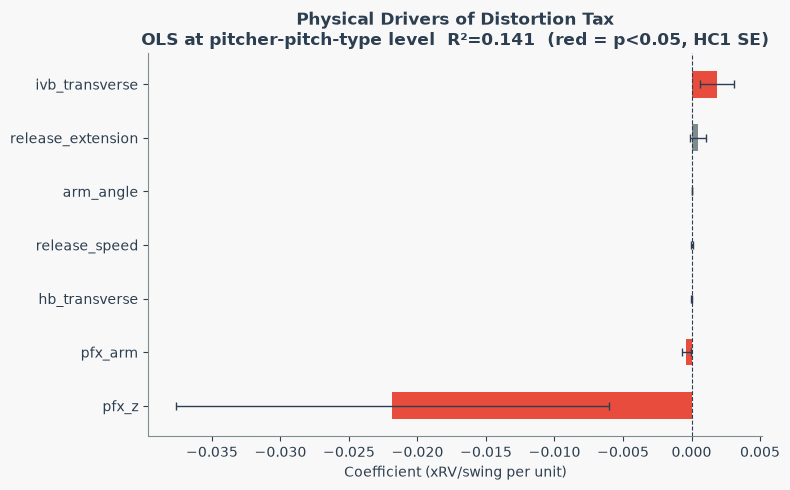

Saved results/plots/diagnostics/physical_drivers_ols.png


In [5]:
df = merged().copy()
df["pfx_arm"]   = np.where(df["pitcher_throws"] == "R",  df["pfx_x"], -df["pfx_x"])
df["pfx_glove"] = np.where(df["pitcher_throws"] == "R", -df["pfx_x"],  df["pfx_x"])

pt_agg = (df[df["distortion_tax"].notna() & df["pfx_x"].notna()]
          .groupby(["pitcher_id", "pitch_type"])
          .agg(n=("distortion_tax",       "size"),
               distortion=("distortion_tax",     "mean"),
               pfx_arm=("pfx_arm",               "mean"),
               pfx_z=("pfx_z",                   "mean"),
               release_speed=("release_speed",   "mean"),
               release_extension=("release_extension", "mean"),
               arm_angle=("arm_angle",           "mean"),
               ivb_transverse=("ivb_transverse", "mean"),
               hb_transverse=("hb_transverse",   "mean"))
          .reset_index()
          .query(f"n >= {MIN_SWINGS // 2}"))

formula = ("distortion ~ pfx_arm + pfx_z + release_speed + "
            "release_extension + arm_angle + ivb_transverse + hb_transverse")
model = smf.ols(formula, pt_agg.dropna()).fit(cov_type="HC1")

driver_out = model.summary2().tables[1].reset_index()
driver_out.columns = ["feature", "coef", "std_err", "t", "p_value", "ci_lower", "ci_upper"]
csv = Path("results/physical_drivers.csv")
if not csv.exists():
    driver_out.to_csv(csv, index=False)

plot_d = driver_out[driver_out["feature"] != "Intercept"].sort_values("coef")
sig    = plot_d["p_value"] < 0.05

fig, ax = plt.subplots(figsize=(8, 5), facecolor=BG)
ax.set_facecolor(BG)
ax.barh(plot_d["feature"], plot_d["coef"],
        xerr=[plot_d["coef"] - plot_d["ci_lower"],
              plot_d["ci_upper"] - plot_d["coef"]],
        color=[RED if s else MID for s in sig],
        height=0.5, capsize=3, error_kw={"ecolor": DARK, "lw": 1})
ax.axvline(0, color=DARK, lw=0.8, ls="--")
ax.set_xlabel("Coefficient (xRV/swing per unit)", color=DARK)
ax.set_title(f"Physical Drivers of Distortion Tax\n"
             f"OLS at pitcher-pitch-type level  R\u00b2={model.rsquared:.3f}  "
             f"(red = p<0.05, HC1 SE)", color=DARK, fontweight="bold")
_spine_clean(ax); ax.tick_params(colors=DARK)
fig.tight_layout()
out = "results/plots/diagnostics/physical_drivers_ols.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}")


In [ ]:
sw = sxrv_extended()[["game_pk", "at_bat_number", "pitch_number",
                        "plate_x", "plate_z", "pitch_group"]]
heat_df = (xrv()
           .dropna(subset=["distortion_tax"])
           .merge(sw, on=["game_pk", "at_bat_number", "pitch_number"], how="inner")
           .dropna(subset=["plate_x", "plate_z"]))

# 5×5 grid: x in [−1.5, 1.5] ft, z in [0.5, 5.0] ft
x_edges = np.linspace(-1.5, 1.5, 6)
z_edges = np.linspace(0.5,  5.0, 6)
heat_df["x_bin"] = pd.cut(heat_df["plate_x"], bins=x_edges, labels=False)
heat_df["z_bin"] = pd.cut(heat_df["plate_z"], bins=z_edges, labels=False)

groups = ["Fastball", "Breaking", "Offspeed"]
fig, axes = plt.subplots(1, 3, figsize=(14, 5), facecolor=BG)
fig.suptitle("Mean distortion tax by plate location and pitch group\n"
             "(darker red = more pitcher advantage from late movement)",
             color=DARK, fontweight="bold", y=1.02)

x_tick_labels = ["−1.2", "−0.6", "0", "+0.6", "+1.2"]
z_tick_labels = ["0.8", "1.6", "2.3", "3.1", "3.9"]
im_ref = None

for ax, grp in zip(axes, groups):
    ax.set_facecolor(BG)
    sub  = heat_df[heat_df["pitch_group"] == grp]
    grid = (sub.groupby(["z_bin", "x_bin"])["distortion_tax"]
               .mean()
               .unstack("x_bin")
               .reindex(index=range(5), columns=range(5)))
    im = ax.imshow(grid.values, origin="lower", aspect="auto",
                   cmap="RdYlGn_r", vmin=-0.15, vmax=0.0)
    if im_ref is None:
        im_ref = im
    ax.set_title(grp, color=DARK, fontweight="bold")
    ax.set_xlabel("← Arm side   Glove side →", color=DARK, fontsize=8)
    if ax is axes[0]:
        ax.set_ylabel("Height (low → high)", color=DARK, fontsize=8)
    ax.set_xticks(range(5)); ax.set_xticklabels(x_tick_labels, color=DARK, fontsize=7)
    ax.set_yticks(range(5)); ax.set_yticklabels(z_tick_labels, color=DARK, fontsize=7)
    # Strike zone outline: x ≈ [−0.71, 0.71] ft → bins ~[1.1, 2.9]; z ≈ [1.5, 3.5] → bins ~[1.1, 3.3]
    ax.add_patch(mpatches.Rectangle((1.1, 1.1), 1.8, 2.2,
                                    linewidth=1.2, edgecolor=DARK, facecolor="none", linestyle="--"))

plt.colorbar(im_ref, ax=axes[-1], label="Mean distortion tax (xRV/swing)", shrink=0.8)
fig.tight_layout()
out = "results/plots/applications/distortion_heatmap_by_zone.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}")

assert Path(out).exists()
brk_mean = heat_df[heat_df["pitch_group"] == "Breaking"]["distortion_tax"].mean()
ff_mean  = heat_df[heat_df["pitch_group"] == "Fastball"]["distortion_tax"].mean()
assert brk_mean < ff_mean, f"Expected Breaking < Fastball: {brk_mean:.4f} vs {ff_mean:.4f}"

In [ ]:

pitchers = pd.read_csv("results/distortion_pitcher.csv").query(f"n_swings >= {MIN_SWINGS}")
pitcher_names = (
    sxrv_extended()[["pitcher_id", "pitcher_full_name"]]
    .drop_duplicates("pitcher_id")
)
pitchers = pitchers.merge(pitcher_names, on="pitcher_id", how="left")

# Drop rows where either metric is missing (pitchers with no BIP in sample)
plot_df = pitchers.dropna(subset=["mean_ev_suppression", "mean_distortion_tax"])

fig, ax = plt.subplots(figsize=(8, 7), facecolor=BG)
ax.set_facecolor(BG)
ax.scatter(
    plot_df["mean_ev_suppression"],
    plot_df["mean_distortion_tax"],
    alpha=0.35, s=18, color=BLUE,
)

# Annotate top-10 by distortion_tax (most negative = best)
top10 = plot_df.nsmallest(10, "mean_distortion_tax")
for _, row in top10.iterrows():
    last = str(row["pitcher_full_name"]).split()[-1] if pd.notna(row["pitcher_full_name"]) else ""
    ax.annotate(
        last,
        xy=(row["mean_ev_suppression"], row["mean_distortion_tax"]),
        xytext=(4, 2), textcoords="offset points",
        fontsize=7, color=DARK, alpha=0.8,
    )

ax.axvline(0, color=MID, lw=0.6, linestyle="--")
ax.axhline(0, color=MID, lw=0.6, linestyle="--")
ax.set_xlabel("Mean EV Suppression (mph, realized − intended)", color=DARK)
ax.set_ylabel("Mean Distortion Tax (xRV/swing)", color=DARK)
ax.set_title(
    "EV Suppression vs. Distortion Tax by Pitcher\n"
    f"Each dot = one pitcher  |  min {MIN_SWINGS} swings",
    color=DARK, fontweight="bold",
)
_spine_clean(ax)
ax.tick_params(colors=DARK)
fig.tight_layout()

out = "results/plots/applications/ev_suppression_scatter.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved {out}")

assert Path(out).exists()
assert len(plot_df) > 100, f"Expected >100 pitchers, got {len(plot_df)}"
# EV suppression and distortion tax should be negatively correlated
# (more EV suppression → more distortion tax)
from scipy.stats import pearsonr
r_ev, _ = pearsonr(plot_df["mean_ev_suppression"], plot_df["mean_distortion_tax"])
assert r_ev < 0, f"Expected negative correlation, got r={r_ev:.3f}"
print(f"EV suppression vs distortion tax r={r_ev:.3f}  PASS")
